## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

In [1]:
import pandas as pd

from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules

# to stop an annoying warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [3]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header=None,             # the file has no header row: line 1 is already a transaction
    names=["basket"],        # name the one column we create
    sep="|",                 # "|" never appears in this file, so each whole line lands in one column
    quoting=csv.QUOTE_NONE,  # treat any quote characters as ordinary text
)

In [4]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [5]:
long = (
    raw
    .assign(basket_id=raw.index)                    # use the row number as the basket ID
    .assign(item=raw["basket"].str.split(","))      # "milk,bread" becomes ["milk", "bread"]
    .explode("item")                                # one row per (basket, item)
    [["basket_id", "item"]]                         # keep only the two columns we need
    .reset_index(drop=True)                         # renumber the rows 0, 1, 2, ...
)

long["item"] = long["item"].str.strip()             # remove stray leading/trailing spaces

long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [6]:
basket = (
    pd.crosstab(
        long["basket_id"],        # one row per basket
        long["item"],             # one column per grocery item
    )
    .astype(bool)                 # 1 becomes True and 0 becomes False
)

basket

item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
basket_id,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
9831,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9832,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [7]:
basket_sizes = (
    basket
    .sum(axis=1)                  # count the True items in each basket row
    .rename("basket_size")        # name the result column
)

basket_sizes

basket_id
0        4
1        3
2        1
3        4
4        4
        ..
9830    17
9831     1
9832    10
9833     4
9834     5
Name: basket_size, Length: 9835, dtype: int64

3. Summarize the distribution of the number of items.

In [8]:
basket_sizes.describe()          # summarize basket size: count, mean, min, max, and quartiles

count    9835.000000
mean        4.409456
std         3.589385
min         1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        32.000000
Name: basket_size, dtype: float64

4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

In [9]:
item_support = (
    basket
    .mean(axis=0)                         # proportion of baskets containing each item
    .sort_values(ascending=False)         # most popular items first
    .rename("support")                    # name the result
)

item_support

item
whole milk               0.255516
other vegetables         0.193493
rolls/buns               0.183935
soda                     0.174377
yogurt                   0.139502
                           ...   
bags                     0.000407
kitchen utensil          0.000407
preservation products    0.000203
baby food                0.000102
sound storage medium     0.000102
Name: support, Length: 169, dtype: float64

<Axes: title={'center': '15 Most Popular Grocery Items'}, xlabel='Support (proportion of baskets)', ylabel='Item'>

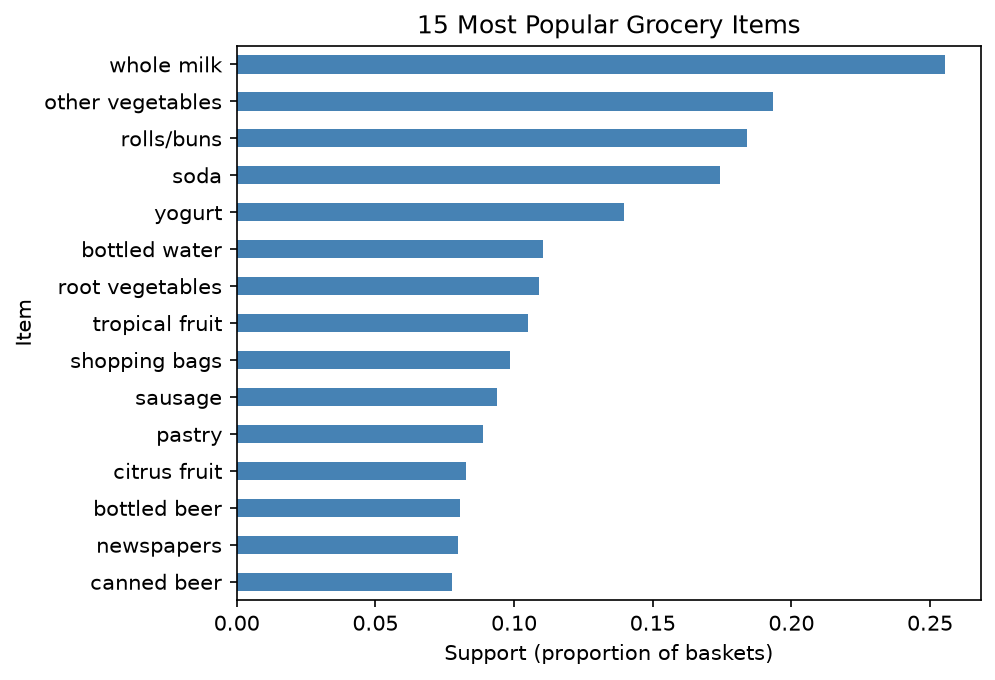

In [10]:
(
    item_support
    .head(15)                             # keep the 15 most popular items
    .sort_values()                        # puts the most popular item at the top
    .plot
    .barh(
        color="steelblue",
        title="15 Most Popular Grocery Items",
        xlabel="Support (proportion of baskets)",
        ylabel="Item",
    )
)

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?


The most popular item is whole milk. It appears in about 25.5% of baskets around one out of every four baskets.

Other very common items are other vegetables, rolls/buns, soda, and yogurt. Since these items appear so often on their own, they will also show up together in many baskets just by chance.

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [11]:
yogurt_to_milk_confidence = (
    basket
    .loc[basket["yogurt"], "whole milk"]    # baskets that contain yogurt: does each also have whole milk?
    .mean()                                 # proportion that are True
)

yogurt_to_milk_confidence


np.float64(0.40160349854227406)

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [12]:
yogurt_to_milk_lift = (
    yogurt_to_milk_confidence
    / item_support["whole milk"]             # compare rule confidence to whole milk's overall support
)

yogurt_to_milk_lift

np.float64(1.5717351405345266)

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [13]:
whole_milk_to_yogurt_confidence = (
    basket
    .loc[basket["whole milk"], "yogurt"]     # baskets with whole milk: does each also have yogurt?
    .mean()
)

whole_milk_to_yogurt_lift = (
    whole_milk_to_yogurt_confidence
    / item_support["yogurt"]                 # compare confidence to yogurt's overall support
)

whole_milk_to_yogurt_confidence, whole_milk_to_yogurt_lift

(np.float64(0.2192598487863112), np.float64(1.5717351405345266))

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [14]:
def support(items, onehot):
    return (
        onehot[items]                  # keep the item columns you requested
        .all(axis=1)                   # True only when a basket has every item
        .mean()                        # share of baskets where that is True
    )


def rule_metrics(antecedent, consequent, onehot):
    rule_support = support(
        antecedent + consequent,       # baskets containing both sides of the rule
        onehot,
    )
    
    confidence = (
        rule_support
        / support(antecedent, onehot)  # P(consequent | antecedent)
    )
    
    lift = (
        confidence
        / support(consequent, onehot)  # compare to the consequent's usual support
    )
    
    return pd.Series(
        {
            "support": rule_support,
            "confidence": confidence,
            "lift": lift,
        }
    )

In [15]:
rule_metrics(
    ["yogurt"],
    ["whole milk"],
    basket
)

support       0.056024
confidence    0.401603
lift          1.571735
dtype: float64

10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

In [16]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [17]:
results = (
    antecedents
    .apply(
        lambda x: rule_metrics(
            [x],                    # turn each item name into a one-item list
            ["whole milk"],
            basket,
        )
    )
    .assign(antecedent=antecedents) # add the left side of each rule
    .loc[:, ["antecedent", "support", "confidence", "lift"]]
    .sort_values("lift", ascending=False)
)

results

,antecedent,support,confidence,lift
0,yogurt,0.056024,0.401603,1.571735
4,other vegetables,0.074835,0.386758,1.513634
2,bottled water,0.034367,0.310948,1.216940
1,rolls/buns,0.056634,0.307905,1.205032
3,soda,0.040061,0.229738,0.899112


12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [18]:
frequent_itemsets = (
    apriori(
        basket,
        min_support=0.01,
        use_colnames=True,
    )
    .assign(n_items=lambda x: x["itemsets"].apply(len))
)

frequent_itemsets


,support,itemsets,n_items
0,0.033452,(UHT-milk),1
1,0.017692,(baking powder),1
2,0.052466,(beef),1
3,0.033249,(berries),1
4,0.026029,(beverages),1
...,...,...,...
328,0.011998,"(tropical fruit, whole milk, root vegetables)",3
329,0.014540,"(yogurt, whole milk, root vegetables)",3
330,0.010473,"(yogurt, soda, whole milk)",3
331,0.015150,"(tropical fruit, yogurt, whole milk)",3


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [19]:
def make_rules(frequent_itemsets, min_confidence):
    return association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=min_confidence,
    )


rules = (
    make_rules(
        frequent_itemsets,
        min_confidence=0.20,
    )
)

len(rules)


234

14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [20]:
rules_display = (
    rules
    .copy()
    .assign(
        antecedent=lambda x: x["antecedents"].apply(
            lambda items: ", ".join(sorted(items))
        ),
        consequent=lambda x: x["consequents"].apply(
            lambda items: ", ".join(sorted(items))
        ),
        transactions=lambda x: (
            x["support"] * len(basket)
        ).round().astype(int),
    )
)

(
    rules_display
    [["antecedent", "consequent", "support", "confidence", "lift", "transactions"]]
    .head(8)
)


,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [21]:
(
    rules_display
    .sort_values("confidence", ascending=False)
    .head(10)
)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,antecedent,consequent,transactions
156,"(citrus fruit, root vegetables)",(other vegetables),0.017692,0.193493,0.010371,0.586207,3.029608,1.0,0.006948,1.949059,0.681990,0.051646,0.486932,0.319903,"citrus fruit, root vegetables",other vegetables,102
184,"(tropical fruit, root vegetables)",(other vegetables),0.021047,0.193493,0.012303,0.584541,3.020999,1.0,0.008231,1.941244,0.683367,0.060835,0.484867,0.324062,"root vegetables, tropical fruit",other vegetables,121
163,"(yogurt, curd)",(whole milk),0.017285,0.255516,0.010066,0.582353,2.279125,1.0,0.005649,1.782567,0.571107,0.038313,0.439011,0.310874,"curd, yogurt",whole milk,99
154,"(butter, other vegetables)",(whole milk),0.020031,0.255516,0.011490,0.573604,2.244885,1.0,0.006371,1.745992,0.565878,0.043512,0.427260,0.309285,"butter, other vegetables",whole milk,113
221,"(tropical fruit, root vegetables)",(whole milk),0.021047,0.255516,0.011998,0.570048,2.230969,1.0,0.006620,1.731553,0.563627,0.045350,0.422484,0.308502,"root vegetables, tropical fruit",whole milk,118
224,"(yogurt, root vegetables)",(whole milk),0.025826,0.255516,0.014540,0.562992,2.203354,1.0,0.007941,1.703594,0.560625,0.054497,0.413006,0.309948,"root vegetables, yogurt",whole milk,143
166,"(other vegetables, domestic eggs)",(whole milk),0.022267,0.255516,0.012303,0.552511,2.162336,1.0,0.006613,1.663694,0.549779,0.046342,0.398928,0.300331,"domestic eggs, other vegetables",whole milk,121
232,"(whipped/sour cream, yogurt)",(whole milk),0.020742,0.255516,0.010880,0.524510,2.052747,1.0,0.005580,1.565719,0.523711,0.040996,0.361316,0.283544,"whipped/sour cream, yogurt",whole milk,107
213,"(rolls/buns, root vegetables)",(whole milk),0.024301,0.255516,0.012710,0.523013,2.046888,1.0,0.006500,1.560804,0.524192,0.047583,0.359305,0.286377,"rolls/buns, root vegetables",whole milk,125
172,"(other vegetables, pip fruit)",(whole milk),0.026131,0.255516,0.013523,0.517510,2.025351,1.0,0.006846,1.543003,0.519843,0.050436,0.351913,0.285217,"other vegetables, pip fruit",whole milk,133


16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [22]:
(
    rules_display
    .sort_values("lift", ascending=False)
    .head(10)
)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,antecedent,consequent,transactions
158,"(citrus fruit, other vegetables)",(root vegetables),0.028876,0.108998,0.010371,0.359155,3.295045,1.0,0.007224,1.390354,0.717225,0.081340,0.280759,0.227152,"citrus fruit, other vegetables",root vegetables,102
209,"(yogurt, other vegetables)",(whipped/sour cream),0.043416,0.071683,0.010168,0.234192,3.267062,1.0,0.007056,1.212206,0.725409,0.096899,0.175058,0.188018,"other vegetables, yogurt",whipped/sour cream,100
186,"(tropical fruit, other vegetables)",(root vegetables),0.035892,0.108998,0.012303,0.342776,3.144780,1.0,0.008391,1.355705,0.707403,0.092791,0.262376,0.227825,"other vegetables, tropical fruit",root vegetables,121
2,(beef),(root vegetables),0.052466,0.108998,0.017387,0.331395,3.040367,1.0,0.011668,1.332628,0.708251,0.120677,0.249603,0.245455,beef,root vegetables,171
156,"(citrus fruit, root vegetables)",(other vegetables),0.017692,0.193493,0.010371,0.586207,3.029608,1.0,0.006948,1.949059,0.681990,0.051646,0.486932,0.319903,"citrus fruit, root vegetables",other vegetables,102
184,"(tropical fruit, root vegetables)",(other vegetables),0.021047,0.193493,0.012303,0.584541,3.020999,1.0,0.008231,1.941244,0.683367,0.060835,0.484867,0.324062,"root vegetables, tropical fruit",other vegetables,121
190,(root vegetables),"(other vegetables, whole milk)",0.108998,0.074835,0.023183,0.212687,2.842082,1.0,0.015026,1.175091,0.727435,0.144304,0.149002,0.261235,root vegetables,"other vegetables, whole milk",228
189,"(other vegetables, whole milk)",(root vegetables),0.074835,0.108998,0.023183,0.309783,2.842082,1.0,0.015026,1.290900,0.700572,0.144304,0.225347,0.261235,"other vegetables, whole milk",root vegetables,228
155,(butter),"(other vegetables, whole milk)",0.055414,0.074835,0.011490,0.207339,2.770630,1.0,0.007343,1.167164,0.676562,0.096747,0.143223,0.180436,butter,"other vegetables, whole milk",113
164,"(whole milk, curd)",(yogurt),0.026131,0.139502,0.010066,0.385214,2.761356,1.0,0.006421,1.399671,0.654974,0.064706,0.285546,0.228686,"curd, whole milk",yogurt,99


17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [23]:
interesting_rules = (
    rules_display
    .query("confidence >= 0.30 and lift >= 1.5")
    .sort_values("lift", ascending=False)
)

interesting_rules


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,antecedent,consequent,transactions
158,"(citrus fruit, other vegetables)",(root vegetables),0.028876,0.108998,0.010371,0.359155,3.295045,1.0,0.007224,1.390354,0.717225,0.081340,0.280759,0.227152,"citrus fruit, other vegetables",root vegetables,102
186,"(tropical fruit, other vegetables)",(root vegetables),0.035892,0.108998,0.012303,0.342776,3.144780,1.0,0.008391,1.355705,0.707403,0.092791,0.262376,0.227825,"other vegetables, tropical fruit",root vegetables,121
2,(beef),(root vegetables),0.052466,0.108998,0.017387,0.331395,3.040367,1.0,0.011668,1.332628,0.708251,0.120677,0.249603,0.245455,beef,root vegetables,171
156,"(citrus fruit, root vegetables)",(other vegetables),0.017692,0.193493,0.010371,0.586207,3.029608,1.0,0.006948,1.949059,0.681990,0.051646,0.486932,0.319903,"citrus fruit, root vegetables",other vegetables,102
184,"(tropical fruit, root vegetables)",(other vegetables),0.021047,0.193493,0.012303,0.584541,3.020999,1.0,0.008231,1.941244,0.683367,0.060835,0.484867,0.324062,"root vegetables, tropical fruit",other vegetables,121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,(onions),(whole milk),0.031012,0.255516,0.012100,0.390164,1.526965,1.0,0.004176,1.220794,0.356151,0.044090,0.180861,0.218759,onions,whole milk,119
72,(hygiene articles),(whole milk),0.032944,0.255516,0.012811,0.388889,1.521975,1.0,0.004394,1.218247,0.354642,0.046477,0.179148,0.219514,hygiene articles,whole milk,126
17,(brown bread),(whole milk),0.064870,0.255516,0.025216,0.388715,1.521293,1.0,0.008641,1.217899,0.366435,0.085429,0.178914,0.243701,brown bread,whole milk,248
106,(other vegetables),(whole milk),0.193493,0.255516,0.074835,0.386758,1.513634,1.0,0.025394,1.214013,0.420750,0.200000,0.176286,0.339817,other vegetables,whole milk,736


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

For the rule **{yogurt} → {whole milk}**, support is **0.0560**, meaning about **5.6%** of all baskets contain both yogurt and whole milk. Confidence is **0.4016**, meaning about **40.2%** of baskets containing yogurt also contain whole milk. Lift is **1.57**, so customers who buy yogurt are about **57% more likely** to buy whole milk than a typical customer.


19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

In [24]:
yogurt_rules = (
    interesting_rules
    .loc[
        lambda x: (
            x["antecedent"].str.contains("yogurt")
            | x["consequent"].str.contains("yogurt")
        )
    ]
    .sort_values("lift", ascending=False)
)

yogurt_rules


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,antecedent,consequent,transactions
164,"(whole milk, curd)",(yogurt),0.026131,0.139502,0.010066,0.385214,2.761356,1.0,0.006421,1.399671,0.654974,0.064706,0.285546,0.228686,"curd, whole milk",yogurt,99
191,"(yogurt, root vegetables)",(other vegetables),0.025826,0.193493,0.012913,0.500000,2.584078,1.0,0.007916,1.613015,0.629266,0.062562,0.380043,0.283368,"root vegetables, yogurt",other vegetables,127
230,"(tropical fruit, whole milk)",(yogurt),0.042298,0.139502,0.015150,0.358173,2.567516,1.0,0.009249,1.340701,0.637483,0.090909,0.254122,0.233387,"tropical fruit, whole milk",yogurt,149
207,"(whipped/sour cream, yogurt)",(other vegetables),0.020742,0.193493,0.010168,0.490196,2.533410,1.0,0.006154,1.581995,0.618096,0.049826,0.367887,0.271372,"whipped/sour cream, yogurt",other vegetables,100
208,"(whipped/sour cream, other vegetables)",(yogurt),0.028876,0.139502,0.010168,0.352113,2.524073,1.0,0.006139,1.328160,0.621769,0.064267,0.247079,0.212499,"other vegetables, whipped/sour cream",yogurt,100
202,"(tropical fruit, other vegetables)",(yogurt),0.035892,0.139502,0.012303,0.342776,2.457146,1.0,0.007296,1.309293,0.615101,0.075436,0.236229,0.215484,"other vegetables, tropical fruit",yogurt,121
233,"(whipped/sour cream, whole milk)",(yogurt),0.032232,0.139502,0.010880,0.337539,2.419607,1.0,0.006383,1.298943,0.606250,0.067636,0.230143,0.207764,"whipped/sour cream, whole milk",yogurt,107
162,"(citrus fruit, whole milk)",(yogurt),0.030503,0.139502,0.010269,0.336667,2.413350,1.0,0.006014,1.297233,0.604064,0.064290,0.229129,0.205141,"citrus fruit, whole milk",yogurt,101
47,(curd),(yogurt),0.053279,0.139502,0.017285,0.324427,2.325615,1.0,0.009853,1.273732,0.602085,0.098494,0.214905,0.224167,curd,yogurt,170
7,(berries),(yogurt),0.033249,0.139502,0.010574,0.318043,2.279848,1.0,0.005936,1.261807,0.580681,0.065204,0.207486,0.196922,berries,yogurt,104


---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).